# Physics 2B: Conservation Laws

The loss sees only the direction of the gradient, so it fixes a conserved quantity up to its scale and offset, and the regulariser shrinks the scale during training (here to about 1e-6). Pruning compares attribution scores with absolute thresholds; below about 1e-4 the constant in their denominator dominates the scores, so `train` rescales the output to unit variance before pruning. Each seed finds its own conserved quantity.

In [1]:
import torch
from tqdm import tqdm
from xkan import KANNetwork, record_activations
from xkan.losses import KANRegularizer
from xkan.nn import update_grids
from xkan.train import LBFGS
from xkan.utils import batch_jacobian, ex_round
from xkan.viz import plot
from xkan.interp import prune
from xkan.symbolic import auto_symbolic, fix_symbolic, unfix_symbolic, symbolic_formula
from sympy import expand

torch.use_deterministic_algorithms(True)

loss_fn = lambda v1, v2: torch.mean(torch.sum(v1 * v2, dim=1)**2)


def get_grad_normalized(model, x):
    grad = batch_jacobian(model, x, create_graph=True)
    grad_normalized = grad/torch.linalg.norm(grad, dim=1, keepdim=True)
    return grad_normalized


def train(seed, steps=50, lamb=1e-2):
    model = KANNetwork([4, [0, 2], 1], seed=seed, base_fun='identity')

    # the model learns a conserved quantity of the flow of two oscillators, e.g. H = 1/2 * (x**2 + p**2)
    torch.manual_seed(seed)
    x = torch.rand(1000,4) * 2 - 1
    flow = torch.cat([x[:,[1]], -x[:,[0]], x[:,[3]], -x[:,[2]]], dim=1)
    flow = flow/torch.linalg.norm(flow, dim=1, keepdim=True)

    # pykan's regulariser (l1 and entropy of the edges' scales, plus the mean |coef|), from recorded activations
    regularizer = KANRegularizer(l1=1., coef=1.)
    optimizer = LBFGS(model.parameters(), lr=1, history_size=10, line_search_fn="strong_wolfe", tolerance_grad=1e-32, tolerance_change=1e-32, tolerance_ys=1e-32)

    def closure():
        global cq_loss, reg_loss
        optimizer.zero_grad()
        grad = get_grad_normalized(model, x)
        cq_loss = loss_fn(grad, flow)
        with record_activations(model) as rec:
            model(x)
        reg_loss = regularizer(model, rec)
        objective = cq_loss + lamb * reg_loss
        objective.backward()
        return objective

    pbar = tqdm(range(steps), desc='description', ncols=100)
    for _ in pbar:
        # update grid
        if _ < 5 and _ % 20 == 0:
            update_grids(model, x)
        optimizer.step(closure)
        pbar.set_description("| cq_loss: %.2e | reg_loss: %.2e |" % (cq_loss.item(), reg_loss.item()))
    print("| cq_loss: %.2e | reg_loss: %.2e |" % (cq_loss.item(), reg_loss.item()))

    # rescale the output to zero mean and unit variance (the output edges' scales and the output bias)
    with torch.no_grad():
        std = model(x).std()
        model.layers[-1].scale_base /= std
        model.layers[-1].scale_sp /= std
        model.node_bias[-1] -= model(x).mean()
    print("output std before rescaling: %.1e" % std)
    return model, x


def fix_output_edges(model, x):
    # the output edges see products of small activations: over that narrow range they are linear, whatever
    # auto_symbolic picked
    for i in range(model.width_in[1]):
        unfix_symbolic(model, 1, i, 0)
        fix_symbolic(model, 1, i, 0, 'x', x)

| cq_loss: 8.38e-04 | reg_loss: 1.79e+00 |
output std before rescaling: 2.9e-06


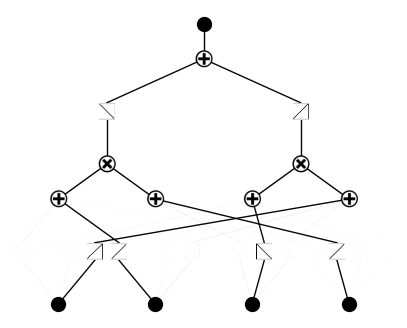

In [2]:
model, x = train(12)
plot(model, x);

In [3]:
model = prune(model, x, edge_th=5e-2)
auto_symbolic(model, x)

fixing (0,0,0) with 0
fixing (0,0,1) with 0
fixing (0,0,2) with 0
fixing (0,1,1) with 0
fixing (0,1,2) with 0


fixing (0,1,3) with 0
fixing (0,2,0) with 0
fixing (0,2,1) with 0
fixing (0,2,3) with 0
fixing (0,3,0) with 0


fixing (0,3,2) with 0
fixing (0,3,3) with 0


fixing (0,0,3) with x, r2=0.9995226860046387, c=1


fixing (0,1,0) with x, r2=0.9999781847000122, c=1


fixing (0,2,2) with x, r2=0.9998669624328613, c=1


fixing (0,3,1) with x, r2=0.9999626278877258, c=1


fixing (1,0,0) with x, r2=0.9999220967292786, c=1


fixing (1,1,0) with x, r2=1.0000001192092896, c=1


{(0, 0, 3): ('x', np.float64(0.9995226860046387), np.int64(1)),
 (0, 1, 0): ('x', np.float64(0.9999781847000122), np.int64(1)),
 (0, 2, 2): ('x', np.float64(0.9998669624328613), np.int64(1)),
 (0, 3, 1): ('x', np.float64(0.9999626278877258), np.int64(1)),
 (1, 0, 0): ('x', np.float64(0.9999220967292786), np.int64(1)),
 (1, 1, 0): ('x', np.float64(1.0000001192092896), np.int64(1))}

In [4]:
fix_output_edges(model, x)
ex_round(expand(symbolic_formula(model)[0][0]), 3)

-2.135*x_1*x_3 + 0.018*x_1 - 2.14*x_2*x_4 - 0.007*x_2 + 0.015*x_3 - 0.002*x_4 - 0.05

| cq_loss: 2.46e-04 | reg_loss: 2.11e+00 |
output std before rescaling: 9.1e-07


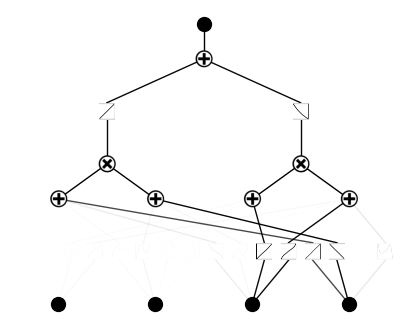

In [5]:
model, x = train(0)
plot(model, x);

In [6]:
model = prune(model, x, edge_th=5e-2)
auto_symbolic(model, x)

fixing (0,0,0) with 0
fixing (0,0,1) with 0
fixing (0,0,2) with 0
fixing (0,0,3) with 0
fixing (0,1,0) with 0
fixing (0,1,1) with 0


fixing (0,1,2) with 0
fixing (0,1,3) with 0
fixing (0,2,0) with 0
fixing (0,2,1) with 0
fixing (0,3,2) with 0
fixing (0,3,3) with 0


fixing (0,2,2) with x, r2=0.9986817836761475, c=1


fixing (0,2,3) with x, r2=0.993462085723877, c=1


fixing (0,3,0) with x, r2=0.9993937015533447, c=1


fixing (0,3,1) with x, r2=0.9999563694000244, c=1


fixing (1,0,0) with x, r2=0.9999985098838806, c=1


fixing (1,1,0) with exp, r2=0.999987781047821, c=2


{(0, 2, 2): ('x', np.float64(0.9986817836761475), np.int64(1)),
 (0, 2, 3): ('x', np.float64(0.993462085723877), np.int64(1)),
 (0, 3, 0): ('x', np.float64(0.9993937015533447), np.int64(1)),
 (0, 3, 1): ('x', np.float64(0.9999563694000244), np.int64(1)),
 (1, 0, 0): ('x', np.float64(0.9999985098838806), np.int64(1)),
 (1, 1, 0): ('exp', np.float64(0.999987781047821), np.int64(2))}

In [7]:
fix_output_edges(model, x)
ex_round(expand(symbolic_formula(model)[0][0]), 3)

-2.154*x_3**2 - 0.006*x_3 - 2.317*x_4**2 - 0.01*x_4 + 1.45

| cq_loss: 3.05e-03 | reg_loss: 2.77e+00 |
output std before rescaling: 1.5e-06


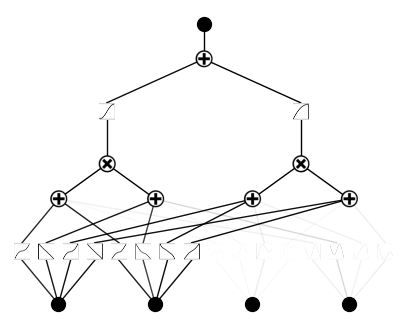

In [8]:
model, x = train(2)
plot(model, x);

In [9]:
model = prune(model, x, edge_th=5e-2)
auto_symbolic(model, x)

fixing (0,2,0) with 0
fixing (0,2,1) with 0
fixing (0,2,2) with 0


fixing (0,2,3) with 0
fixing (0,3,0) with 0
fixing (0,3,2) with 0
fixing (0,3,3) with 0


fixing (0,0,0) with x, r2=0.9261103868484497, c=1


fixing (0,0,1) with x, r2=0.9997346997261047, c=1


fixing (0,0,2) with x, r2=0.9403868913650513, c=1


fixing (0,0,3) with x, r2=0.9989582300186157, c=1


... (4 outputs left out)

fixing (0,3,1) with cos, r2=0.973609209060669, c=2


fixing (1,0,0) with sin, r2=0.9999536871910095, c=2


fixing (1,1,0) with cos, r2=0.9999973773956299, c=2


{(0, 0, 0): ('x', np.float64(0.9261103868484497), np.int64(1)),
 (0, 0, 1): ('x', np.float64(0.9997346997261047), np.int64(1)),
 (0, 0, 2): ('x', np.float64(0.9403868913650513), np.int64(1)),
 (0, 0, 3): ('x', np.float64(0.9989582300186157), np.int64(1)),
 (0, 1, 0): ('x', np.float64(0.9554452896118164), np.int64(1)),
 (0, 1, 1): ('x', np.float64(0.9591709971427917), np.int64(1)),
 (0, 1, 2): ('x', np.float64(0.9861888885498047), np.int64(1)),
 (0, 1, 3): ('x', np.float64(0.9886314272880554), np.int64(1)),
 (0, 3, 1): ('cos', np.float64(0.973609209060669), np.int64(2)),
 (1, 0, 0): ('sin', np.float64(0.9999536871910095), np.int64(2)),
 (1, 1, 0): ('cos', np.float64(0.9999973773956299), np.int64(2))}

In [10]:
fix_output_edges(model, x)
ex_round(expand(symbolic_formula(model)[0][0]), 3)

-1.461*x_1**2 + 0.258*x_1*x_2 + 0.061*x_1*cos(4.324*x_4 - 1.404) + 0.053*x_1 - 1.503*x_2**2 + 0.072*x_2*cos(4.324*x_4 - 1.404) + 0.031*x_2 + 0.003*cos(4.324*x_4 - 1.404) + 1.057